## Problem 18 (14/100 points): Solve the Half-moon Problem

The following cells generate a reproducible half-moon dataset as NumPy arrays, visualize it, and create a shuffled, stratified 80/20 train/test split.

Build a classifier that achieves at least 95% accuracy on both the training and test sets. The interleaving moons call for a nonlinear decision boundary.

Use the provided dataset parameters, seeds, and split unchanged. Fit your model and any preprocessing using only the training data. If you tune your model, use a validation split or cross-validation within the training data; reserve the test set for final evaluation.

This is an open-ended coding problem. Implement your classifier in the final cell and print its train and test accuracy. You may use any of the tools that we have discussed so far in class.

This problem will be graded manually.

In [2]:
import numpy as np
from sklearn.model_selection import train_test_split

import sys
from pathlib import Path

project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "exam" / "__init__.py").exists()
)
sys.path.insert(0, str(project_root))

from exam.data_generators import generate_half_moon_dataset
from exam.data_visualizers import scatter_plot_dataset

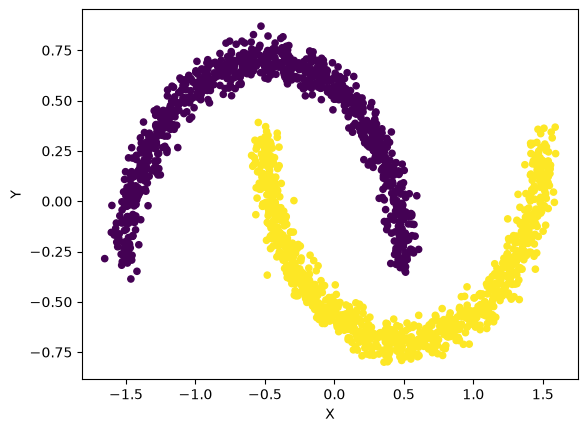

In [3]:
np.random.seed(42)
x_features, y_labels, _ = generate_half_moon_dataset(
    n_samples_per_class=1000,
    n_clusters_per_class=100,
    radius_r=1,
    separation_offset_d=-0.3,
    sigma=0.05,
)

_ = scatter_plot_dataset(x_features, y_labels, x_plot_dimension=0, y_plot_dimension=1)

x_train, x_test, y_train, y_test = train_test_split(
    x_features,
    y_labels,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=y_labels,
)

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10)
)

model.fit(x_train, np.ravel(y_train))

train_predictions = model.predict(x_train)
test_predictions = model.predict(x_test)

print("Train accuracy:", accuracy_score(y_train, train_predictions))
print("Test accuracy:", accuracy_score(y_test, test_predictions))# Your code here

Train accuracy: 1.0
Test accuracy: 1.0
